# Práctica 5: Introducción al análisis frecuencial de señales
**Bioseñales y Sistemas – Bioingeniería, Universidad de Antioquia**

Por Manuela Hernández y Juan Cubides

In [49]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
import scipy.io as sio

# Punto 4.1

Cree una señal que sea la suma de tres componentes sinusoidales con frecuencias de 40, 80 y 160 Hz. Defina la frecuencia de muestreo mínima necesaria para representar la señal, y utilice la frecuencia de muestreo necesaria para representarla apropiadamente. (10%)

Resolviendo el enunciado se pudo obetener que:
Por el teorema de Nyquist, para reconstruir una señal sin aliasing se necesita  
 $F_s > 2F_{max}$  
La componente de mayor frecuencia es 160 Hz, entonces se tiene que  
 
2 x 160= 320 Hz

In [50]:
f1, f2, f3 = 40, 80, 160        # Hz
A1, A2, A3 = 5, 3, 1.5          # V
Fmax = max(f1, f2, f3)
Fs_min = 2*Fmax
print('Frecuencia de muestreo mínima (Nyquist):', Fs_min, 'Hz')

def senal_compuesta(t):
    return (A1*np.sin(2*np.pi*f1*t) +
            A2*np.sin(2*np.pi*f2*t) +
            A3*np.sin(2*np.pi*f3*t))

# Periodo fundamental de la suma: MCD(40, 80, 160) = 40 Hz -> Tp = 25 ms
Tp = 1/np.gcd.reduce([f1, f2, f3])

# Referencia "casi continua" para comparar
t_ref = np.arange(0, 2*Tp, 1/100000)
x_ref = senal_compuesta(t_ref)

Frecuencia de muestreo mínima (Nyquist): 320 Hz


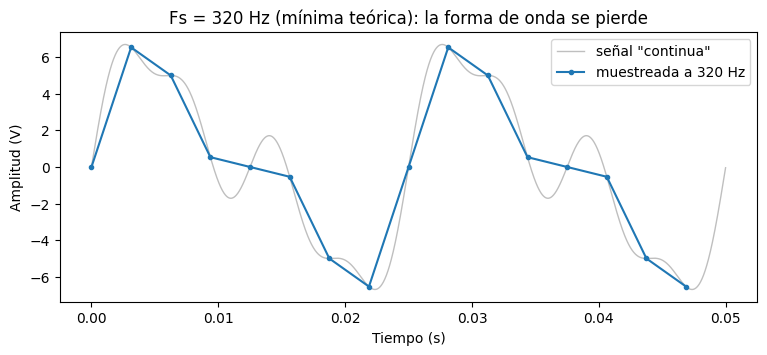

In [51]:
t_320 = np.arange(0, 2*Tp, 1/Fs_min)
x_320 = senal_compuesta(t_320)

plt.figure(figsize=(9, 3.5))
plt.plot(t_ref, x_ref, color='0.75', lw=1, label='señal "continua"')
plt.plot(t_320, x_320, 'o-', ms=3, label=f'muestreada a {Fs_min} Hz')
plt.title('Fs = 320 Hz (mínima teórica): la forma de onda se pierde')
plt.xlabel('Tiempo (s)')
plt.ylabel('Amplitud (V)')
plt.legend(loc='upper right')
plt.show()

Muestreando exactamente a 320 Hz, la componente de 160 Hz queda con solo 2 muestras por ciclo y, según la fase, puede caer siempre sobre los cruces por cero y desaparecer. Por eso la condición es estricta > y en la práctica se usa entre 5 y 10 veces Fmax.

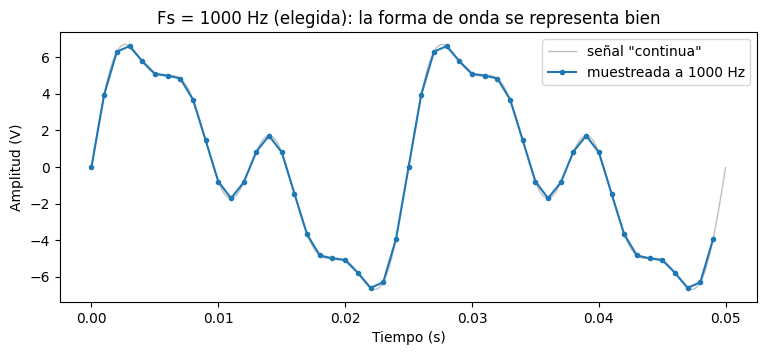

In [52]:
Fs_sel = 1000
t_1000 = np.arange(0, 2*Tp, 1/Fs_sel)
x_1000 = senal_compuesta(t_1000)

plt.figure(figsize=(9, 3.5))
plt.plot(t_ref, x_ref, color='0.75', lw=1, label='señal "continua"')
plt.plot(t_1000, x_1000, 'o-', ms=3, label=f'muestreada a {Fs_sel} Hz')
plt.title('Fs = 1000 Hz (elegida): la forma de onda se representa bien')
plt.xlabel('Tiempo (s)')
plt.ylabel('Amplitud (V)')
plt.legend(loc='upper right')
plt.show()

Fs = 1000 Hz | duración = 0.25 s | N = 250 muestras


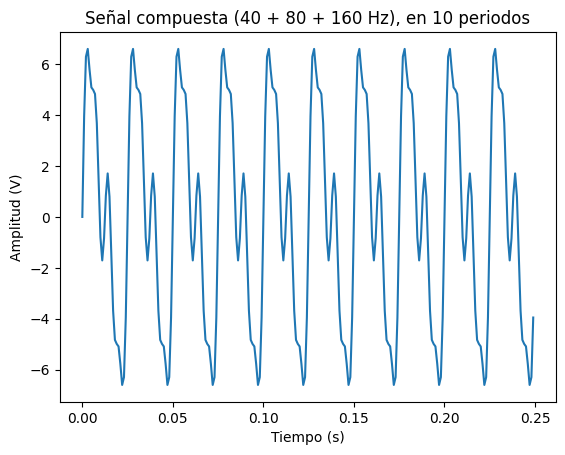

In [53]:
# Señal definitiva: Fs = 1000 Hz y 10 periodos de la señal
Fs = 1000
T = 1/Fs
t = np.arange(0, 10*Tp, T)      # 250 muestras (10 periodos completos)
x = senal_compuesta(t)
N = len(x)
print('Fs =', Fs, 'Hz | duración =', 10*Tp, 's | N =', N, 'muestras')

plt.plot(t, x)
plt.title('Señal compuesta (40 + 80 + 160 Hz), en 10 periodos')
plt.xlabel('Tiempo (s)'); plt.ylabel('Amplitud (V)')
plt.show()

# Punto 4.2
Calcule la transformada de Fourier de la señal y grafique el espectro de frecuencia. Identifique en el espectro las frecuencias que componen la señal (trabaje con 10 periodos de la señal). (10%)

In [54]:
X = np.fft.fft(x)
F = np.arange(0, N)*Fs/N                 

Nmitad = int(np.ceil(N/2))
Fmitad = F[:Nmitad]
Xmitad = X[:Nmitad]
amp = 2*np.abs(Xmitad)/N               

In [55]:
picos, _ = signal.find_peaks(amp, height=0.5)
for k in picos:
    print(f'k = {k:3d} -> F = {Fmitad[k]:6.1f} Hz | |X(k)| = {np.abs(Xmitad[k]):6.1f} | amplitud = {amp[k]:.2f} V')

k =  10 -> F =   40.0 Hz | |X(k)| =  625.0 | amplitud = 5.00 V
k =  20 -> F =   80.0 Hz | |X(k)| =  375.0 | amplitud = 3.00 V
k =  40 -> F =  160.0 Hz | |X(k)| =  187.5 | amplitud = 1.50 V


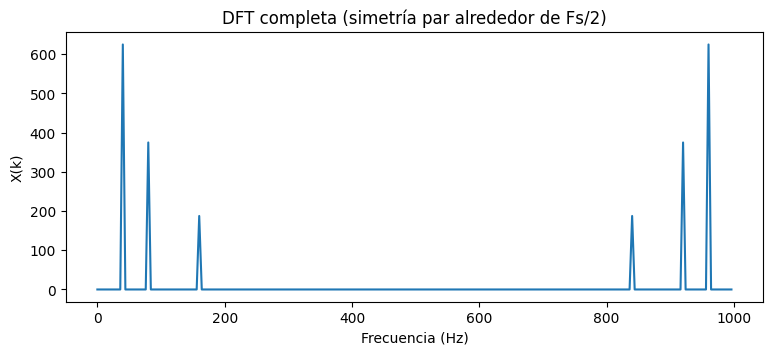

In [56]:
plt.figure(figsize=(9, 3.5))
plt.plot(F, np.abs(X))
plt.title('DFT completa (simetría par alrededor de Fs/2)')
plt.xlabel('Frecuencia (Hz)')
plt.ylabel('X(k)')
plt.show()

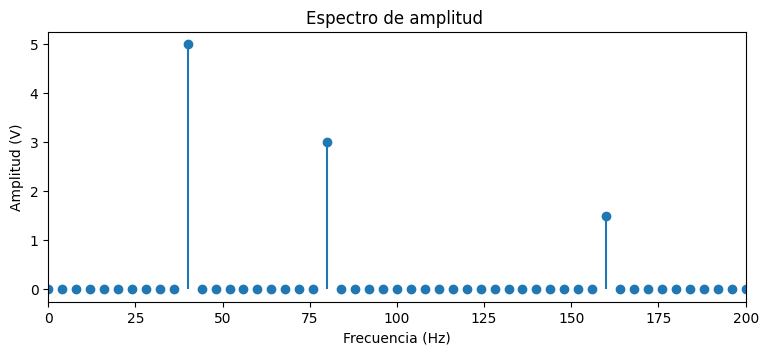

In [57]:
plt.figure(figsize=(9, 3.5))
plt.stem(Fmitad, amp, basefmt=' ')
plt.xlim(0, 200)
plt.title('Espectro de amplitud ')
plt.xlabel('Frecuencia (Hz)')
plt.ylabel('Amplitud (V)')
plt.show()

El espectro muestra tres picos en 40, 80 y 160 Hz que son justo las tres ondas con las que se construyó la señal. La altura de cada pico corresponde a su amplitud (5, 3 y 1,5 V).
Fuera de esos tres picos el espectro vale cero, porque cada frecuencia cae exactamente en una de las "casillas" de la FFT (cada 4 Hz), y así no hay fuga espectral. La mitad derecha de la DFT completa es un espejo de la izquierda porque la señal es real; por eso basta con graficar de 0 a $F_s/2$.

# Punto 4.3
Consulte la función que permite realizar el cálculo de la transformada inversa de Fourier. Aplíquelo a la señal anterior. (10%)

La función es numpy.fft.ifft (también existe otra llamada scipy.fft.ifft), el calculo que realiza es 

$$x(n) = \frac{1}{N}\sum_{k=0}^{N-1} X(k)\, e^{\,j 2\pi k n / N}, \qquad n = 0,\dots,N-1$$

Recibe el vector complejo de la DFT y devuelve un vector complejo; para una señal real la parte imaginaria es solo error numérico (≈ 1e-15), así que se toma np.real. Para señales reales también existe el par np.fft.rfft / np.fft.irfft, que trabaja solo con la mitad positiva del espectro.

Máx - parte imaginaria : 1.7311975498406352e-15
Máx error de reconstrucción: 3.552713678800501e-15


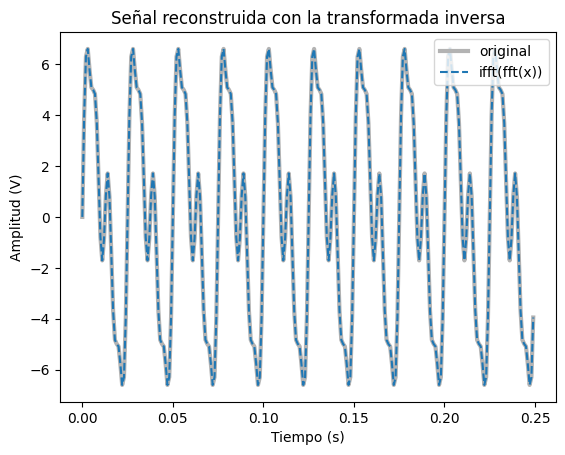

In [58]:
x_rec = np.fft.ifft(X)

print('Máx - parte imaginaria :', np.max(np.abs(np.imag(x_rec))))
print('Máx error de reconstrucción:', np.max(np.abs(np.real(x_rec) - x)))

plt.plot(t, x, lw=3, color='0.7', label='original')
plt.plot(t, np.real(x_rec), '--', label='ifft(fft(x))')
plt.title('Señal reconstruida con la transformada inversa')
plt.xlabel('Tiempo (s)'); plt.ylabel('Amplitud (V)')
plt.legend(); plt.show()

La señal reconstruida coincide con la original (error del orden de 10^-15). La DFT es una transformación invertible: no se pierde información al pasar al dominio de la frecuencia y volver.

# Punto 4.4 
¿Podría decir que las siguientes líneas aplican un filtro? ¿Por qué? Extraiga de manera similar cada una de las componentes de la señal.

```python
F1 = np.fft.fft(x)
F2 = np.zeros((len(F1)))
F2[9:13] = F1[9:13]
xr = np.fft.ifft(F2)
```

Bins conservados: [9, 10, 11, 12] -> ['36 Hz', '40 Hz', '44 Hz', '48 Hz']
Amplitud máx. de la parte real : 2.495 V
Amplitud máx. de la parte imag.: 2.48 V


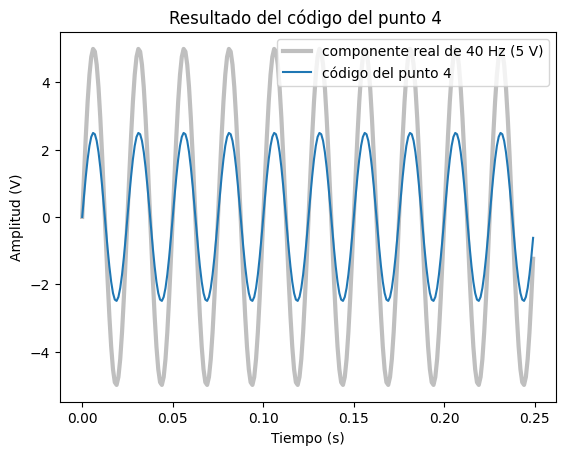

In [59]:
F1 = np.fft.fft(x)
F2 = np.zeros((len(F1)), dtype=complex)   # dtype complejo: si no, numpy va a descarta la parte imaginaria
F2[9:13] = F1[9:13]
xr = np.fft.ifft(F2)

print('Bins conservados:', list(range(9, 13)), '->', [f'{k*Fs/N:.0f} Hz' for k in range(9, 13)])
print('Amplitud máx. de la parte real :', np.max(np.real(xr)).round(3), 'V')
print('Amplitud máx. de la parte imag.:', np.max(np.imag(xr)).round(3), 'V')

fig, ax = plt.subplots()
ax.plot(t, A1*np.sin(2*np.pi*f1*t), lw=3, color='0.75', label='componente real de 40 Hz (5 V)')
ax.plot(t, np.real(xr), label='código del punto 4 ')
ax.set(xlabel='Tiempo (s)', ylabel='Amplitud (V)', title='Resultado del código del punto 4 ')
ax.legend(loc='upper right'); plt.show()

Sí, es un filtro. Un filtro deja pasar algunas frecuencias y elimina otras, y eso es lo que hace el codigo de este punto.

FFT pasa la señal al espectro de frecuencia. Se crea un espectro vacío  y solo se copian las casillas 9 a 12.
Como cada casilla mide F_s/N = 1000/250 = 4 Hz, esas casillas son 36, 40, 44 y 48 Hz. Solo queda la onda de 40 Hz las de 80 y 160 Hz se borran.
Por ultimo ifft regresa al dominio del tiempo y entrega la señal filtrada.

El espectro de una señal real tiene dos mitades en espejo, y cada una lleva la mitad de la onda. El código solo copia la mitad izquierda, por eso la onda filtrada sale con la mitad de la amplitud (2,5 V en vez de 5 V) y con una parte imaginaria que no debería tener.

 40 Hz: amplitud = 4.990 V | error vs teórica = 3.0e-14 | máx. imag = 1.0e-15
 80 Hz: amplitud = 2.994 V | error vs teórica = 3.2e-14 | máx. imag = 8.3e-16
160 Hz: amplitud = 1.497 V | error vs teórica = 3.8e-14 | máx. imag = 2.3e-16


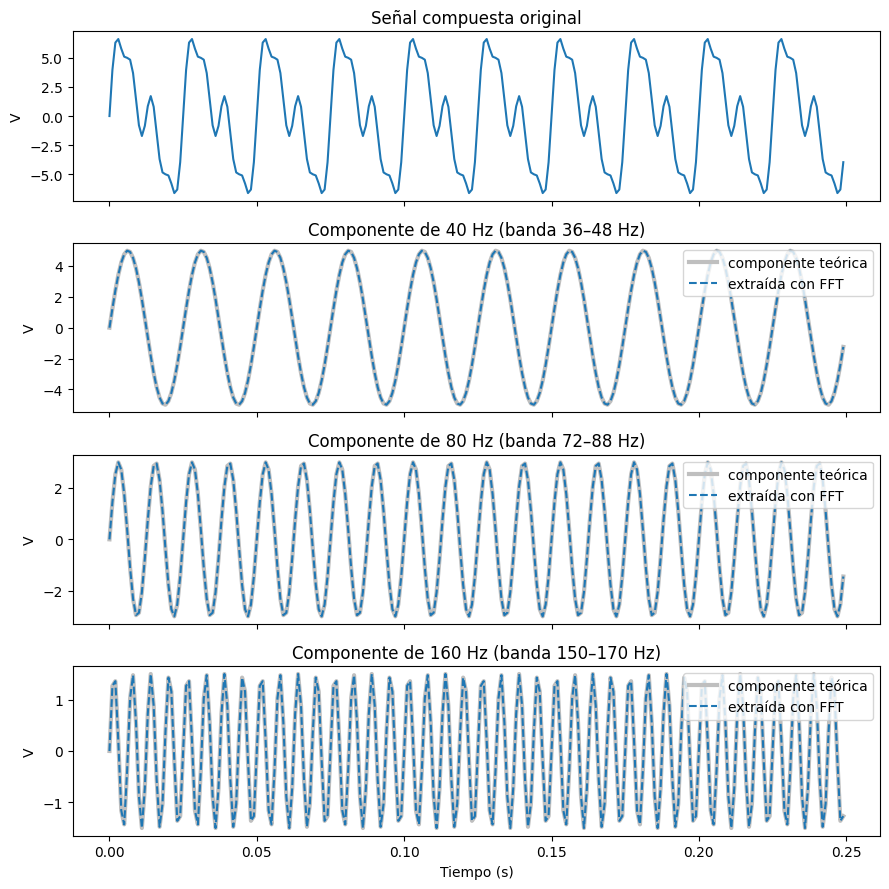

Error de la suma de las 3 componentes vs la señal original: 9.44802342684553e-14


In [60]:
def filtro_fft(x, Fs, f_low, f_high):
    '''Filtro ideal en frecuencia: conserva solo las frecuencias en [f_low, f_high] Hz,
    tanto en la mitad positiva como en su simétrica negativa, para que la salida sea real.'''
    N = len(x)
    X = np.fft.fft(x)
    f = np.fft.fftfreq(N, d=1/Fs)              # frecuencias con signo: 0, +, ..., -, ...
    H = (np.abs(f) >= f_low) & (np.abs(f) <= f_high)
    xf = np.fft.ifft(X*H)
    return np.real(xf), np.max(np.abs(np.imag(xf)))

bandas = {'40 Hz': (36, 48, A1, f1), '80 Hz': (72, 88, A2, f2), '160 Hz': (150, 170, A3, f3)}

fig, axs = plt.subplots(4, 1, figsize=(9, 9), sharex=True)
axs[0].plot(t, x); axs[0].set_title('Señal compuesta original'); axs[0].set_ylabel('V')
suma = np.zeros_like(x)
for ax, (nombre, (fl, fh, Ai, fi)) in zip(axs[1:], bandas.items()):
    comp, imag_max = filtro_fft(x, Fs, fl, fh)
    suma += comp
    ideal = Ai*np.sin(2*np.pi*fi*t)
    ax.plot(t, ideal, lw=3, color='0.75', label='componente teórica')
    ax.plot(t, comp, '--', label='extraída con FFT')
    ax.set_title(f'Componente de {nombre} (banda {fl}–{fh} Hz)'); ax.set_ylabel('V')
    ax.legend(loc='upper right')
    print(f'{nombre:>6}: amplitud = {comp.max():.3f} V | error vs teórica = {np.max(np.abs(comp-ideal)):.1e} | máx. imag = {imag_max:.1e}')
axs[-1].set_xlabel('Tiempo (s)')
plt.tight_layout(); plt.show()

print('Error de la suma de las 3 componentes vs la señal original:', np.max(np.abs(suma - x)))

Con la máscara simétrica, cada componente se recupera con su amplitud correcta (5, 3 y 1,5 V), la parte imaginaria es ≈ 0 y la suma de las tres componentes reconstruye la señal original. Hay que tener en cuenta que en este ejemplo el filtro funciona perfecto porque cada sinusoide cae exactamente en un bin; en una señal real (como el ECG), un filtro ideal en frecuencia con bordes abruptos produce oscilaciones (fenómeno de Gibbs) en el tiempo.


# Punto 4.5
Cree una función que calcule manualmente el periodograma de Welch de una señal discreta (usando la DFT), explique paso a paso el algoritmo. Pruébelo en una de las señales construidas anteriormente.

In [61]:
import pandas as pd
from scipy.signal import welch

### Algoritmo paso a paso
El periodograma de Welch estima cómo se reparte la potencia de una señal entre las distintas frecuencias. Si se calculara una sola DFT de toda la señal, se obtendría un espectro muy ruidoso, porque cada valor depende de un único cálculo. El método de Welch soluciona esto dividiendo la señal en pedazos, calculando el espectro de cada pedazo y promediándolos. Es la misma idea de repetir una medición varias veces y promediar para reducir el error.

El primer paso es construir una ventana de Hann de L muestras, definida como w[n] = 0,5 − 0,5·cos(2πn/L). Esta ventana vale cero en los extremos y uno en el centro. Al multiplicar un segmento por ella, sus bordes bajan suavemente a cero y se evita el salto brusco que aparecería al cortar la señal. Ese salto produce fuga espectral: la energía de una frecuencia se "riega" hacia las frecuencias vecinas.

Luego la señal se divide en segmentos de L muestras que se solapan D muestras, de modo que cada segmento empieza L − D muestras después del anterior. Cada segmento se multiplica por la ventana y se le calcula la DFT con np.fft.fft. Con la DFT se obtiene el periodograma del segmento, |X[k]|² / (fs·Σw²). Dividir por la frecuencia de muestreo fs deja el resultado en unidades de potencia por hertz (V²/Hz). Dividir por Σw², la energía de la ventana, compensa la potencia que la ventana le quita a la señal al atenuar sus bordes.

Después se promedian los periodogramas de todos los segmentos; ese promedio es el periodograma de Welch. Por último, como la señal es real, su espectro es simétrico y la mitad negativa repite la positiva. Por eso solo se conservan las frecuencias de 0 a fs/2, y las intermedias se multiplican por 2 para no perder la potencia que estaba en la mitad negativa. Los valores en 0 Hz y en fs/2 no se duplican, porque no tienen pareja en la otra mitad.

In [62]:
def ventana_hann(L):
    n = np.arange(L)
    return 0.5 - 0.5 * np.cos(2 * np.pi * n / L)


def welch_manual(x, fs, L, D):
    """Periodograma de Welch calculado con la DFT.
    x: señal, fs: frecuencia de muestreo (Hz),
    L: muestras por segmento (se recomienda que sea par), D: muestras de solapamiento."""
    w = ventana_hann(L)                      
    paso = L - D
    n_segmentos = (len(x) - L) // paso + 1

    suma = np.zeros(L)
    for k in range(n_segmentos):
        inicio = k * paso
        segmento = x[inicio:inicio + L]                      # segmento k
        X_seg = np.fft.fft(segmento * w)                     # ventana + DFT
        suma = suma + np.abs(X_seg)**2 / (fs * np.sum(w**2)) # periodograma del segmento
    P = suma / n_segmentos                    # promedio de los segmentos

    mitad = L // 2 + 1                        # solo de 0 a fs/2
    f = np.arange(mitad) * fs / L
    P = P[:mitad]
    P[1:-1] = 2 * P[1:-1]
    return f, P

### Prueba con la señal del punto 4.1
Se usa la señal compuesta del punto 4.1: las componentes de 40, 80 y 160 Hz con amplitudes de 5, 3 y 1,5 V, muestreada a 1000 Hz durante 10 periodos, es decir, 250 muestras. Se usan segmentos de L = 100 muestras, con una resolución de fs/L = 10 Hz, y un solapamiento de D = 50 muestras, el 50 %. Con estos valores, las tres frecuencias de la señal caen exactamente en frecuencias del periodograma, que van de 10 en 10 Hz.

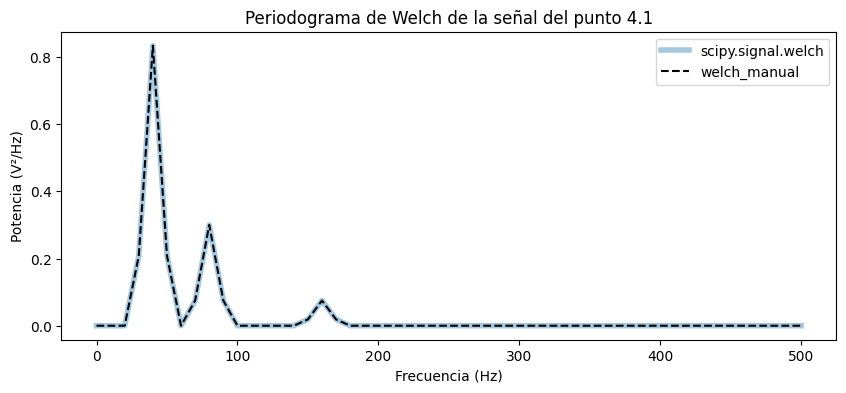

40 Hz: potencia = 0.8333 V²/Hz
80 Hz: potencia = 0.3000 V²/Hz
160 Hz: potencia = 0.0750 V²/Hz
Relación de potencias 40 Hz / 80 Hz: 2.78 | (5/3)² = 2.78
Diferencia máxima entre las dos funciones: 1.1102230246251565e-16


In [63]:
L1 = 100      # 0,1 s -> resolución de 10 Hz
D1 = 50       # 50 % de solapamiento
f_manual, P_manual = welch_manual(x, Fs, L1, D1)
f_lib, P_lib = welch(x, Fs, window='hann', nperseg=L1, noverlap=D1, detrend=False)

plt.figure(figsize=(10, 4))
plt.plot(f_lib, P_lib, linewidth=4, alpha=0.4, label='scipy.signal.welch')
plt.plot(f_manual, P_manual, 'k--', label='welch_manual')
plt.xlabel('Frecuencia (Hz)')
plt.ylabel('Potencia (V²/Hz)')
plt.title('Periodograma de Welch de la señal del punto 4.1')
plt.legend()
plt.show()

picos = [40, 80, 160]
for fp in picos:
    k = np.argmin(np.abs(f_manual - fp))
    print(f"{fp} Hz: potencia = {P_manual[k]:.4f} V²/Hz")
print("Relación de potencias 40 Hz / 80 Hz:", round(P_manual[4] / P_manual[8], 2), "| (5/3)² =", round((5/3)**2, 2))
print("Diferencia máxima entre las dos funciones:", np.max(np.abs(P_manual - P_lib)))

### Análisis
El periodograma de Welch muestra tres picos, exactamente en 40, 80 y 160 Hz, las mismas frecuencias que componen la señal del punto 4.1. A diferencia del espectro de amplitud del punto 4.2, aquí el eje vertical es potencia, que es proporcional al cuadrado de la amplitud. Por eso los picos no guardan la proporción 5 : 3 : 1,5 de las amplitudes, sino la de sus cuadrados: la potencia del pico de 40 Hz es (5/3)² ≈ 2,78 veces la del pico de 80 Hz, como muestra el resultado numérico.

Los picos se ven más anchos que en el espectro del punto 4.2. Esto ocurre porque cada segmento tiene solo 100 muestras, así que la resolución es de 10 Hz en lugar de 4 Hz, y además la ventana de Hann ensancha un poco cada pico a cambio de reducir la fuga espectral. Es el compromiso típico del método de Welch: se gana una estimación más estable al promediar, pero se pierde resolución en frecuencia.

Finalmente, la función manual y scipy.signal.welch dan el mismo resultado: las curvas se superponen y la diferencia máxima es del orden de 10⁻¹⁶, que corresponde solo al error de redondeo del computador. Esto confirma que el algoritmo está bien implementado. En la comparación se usó detrend=False, porque por defecto la función de la librería le resta la media a cada segmento y la función manual no lo hace.

# Punto 4.6
El archivo adjunto (senecg.mat) contiene una señal de ECG adquirida a una frecuencia de muestreo de 250 Hz. Realice un análisis en frecuencia de la señal usando periodogramas de Welch y determine si es necesario eliminar ruido, en tal caso, elimínelo de la forma que se mostró antes y compruebe que lo haya realizado, calcule la transformada inversa de Fourier de la señal filtrada y compruebe con el periodograma. (Usar una ventana Hanning, y justificar la elección del solapamiento y el ancho de la ventana) (25%). Compare el método de la librería con la función creada en el punto anterior.


Número de muestras: 1250
Duración: 5.0 s


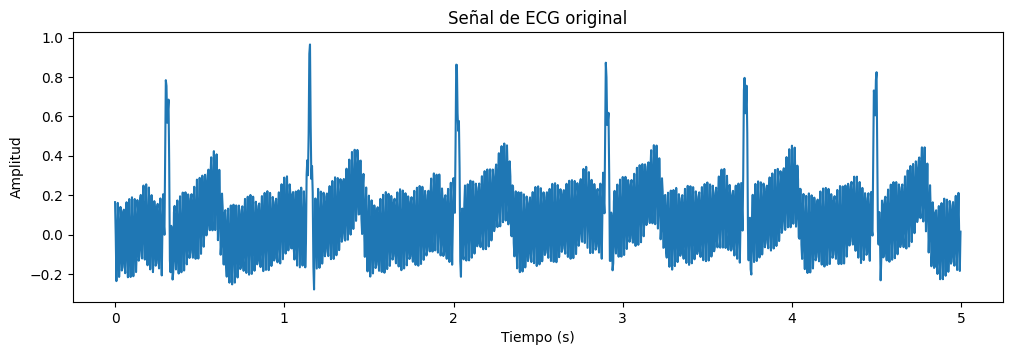

In [64]:
datos = sio.loadmat('senecg.mat')
ecg = datos['ECG'].ravel()      # ravel convierte la columna del .mat en un vector
fs = 250                        # Hz
t_ecg = np.arange(len(ecg)) / fs

print("Número de muestras:", len(ecg))
print("Duración:", len(ecg) / fs, "s")

plt.figure(figsize=(12, 3.5))
plt.plot(t_ecg, ecg)
plt.xlabel('Tiempo (s)')
plt.ylabel('Amplitud')
plt.title('Señal de ECG original')
plt.show()

La señal tiene 1250 muestras, es decir, 5 s de registro, y en ella se ven 6 latidos, lo que corresponde a una frecuencia cardíaca de unos 70 latidos por minuto. Se distinguen los complejos QRS y las ondas T. Sin embargo, a lo largo de todo el registro la señal tiene un grosor formado por oscilaciones muy rápidas y regulares, que no corresponden a la actividad eléctrica del corazón. Es el primer indicio de que la señal tiene ruido, y el análisis en frecuencia permite confirmarlo e identificarlo.

### Elección del ancho de la ventana y del solapamiento
Se escogió una ventana de L = 250 muestras, es decir, 1 s. Con ella, la resolución en frecuencia es fs/L = 1 Hz, suficiente para ubicar con precisión un pico de ruido y para ver la forma del espectro del ECG, cuya información está entre 0,5 y 40 Hz. Además, un segundo contiene al menos un latido completo. Una ventana más larga, de 2 s, mejoraría la resolución a 0,5 Hz, pero como la señal dura solo 5 s quedarían muy pocos segmentos para promediar y el periodograma sería más ruidoso. Una ventana más corta tendría el problema contrario más segmentos, pero con una resolución peor que 1 Hz.

El solapamiento elegido es de D = 125 muestras, es decir, del 50 %. La ventana de Hann vale casi cero en sus extremos, así que, sin solapamiento, las muestras ubicadas en los bordes de cada segmento casi no se tendrían en cuenta. Con un 50 % de solapamiento, las ventanas de Hann consecutivas suman un valor constante, de modo que todas las muestras de la señal pesan lo mismo en el resultado. Además, el número de segmentos pasa de 5 a 9, y al promediar más segmentos la estimación es más estable.

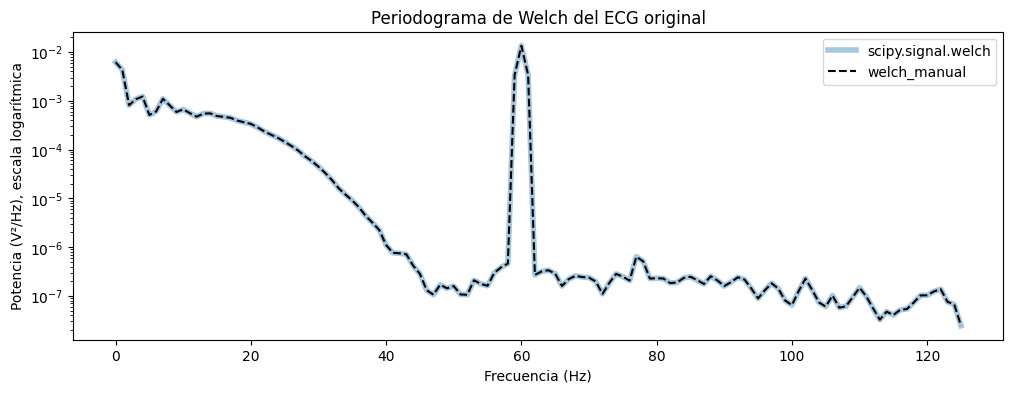

Frecuencia con mayor potencia: 60.0 Hz
Diferencia máxima entre la función manual y la librería: 1.214306433183765e-17


In [65]:
L = 250     # 1 s -> resolución de 1 Hz
D = 125     # 50 % de solapamiento

f_man, P_man = welch_manual(ecg, fs, L, D)
f_lib, P_lib = welch(ecg, fs, window='hann', nperseg=L, noverlap=D, detrend=False)

plt.figure(figsize=(12, 4))
plt.semilogy(f_lib, P_lib, linewidth=4, alpha=0.4, label='scipy.signal.welch')
plt.semilogy(f_man, P_man, 'k--', label='welch_manual')
plt.xlabel('Frecuencia (Hz)')
plt.ylabel('Potencia (V²/Hz), escala logarítmica')
plt.title('Periodograma de Welch del ECG original')
plt.legend()
plt.show()

print("Frecuencia con mayor potencia:", f_man[np.argmax(P_man)], "Hz")
print("Diferencia máxima entre la función manual y la librería:", np.max(np.abs(P_man - P_lib)))

### Análisis del periodograma
El periodograma confirma que sí es necesario eliminar ruido. La mayor parte de la potencia del ECG está entre 0 y unos 40 Hz y disminuye poco a poco al aumentar la frecuencia, que es el comportamiento esperado: la onda P, la onda T y la frecuencia cardíaca aportan las frecuencias bajas, y el complejo QRS, al ser más rápido, aporta las frecuencias entre unos 5 y 40 Hz. Por encima de 40 Hz la potencia es muy baja, salvo por un pico muy fuerte y angosto en 60 Hz, unas 10.000 veces mayor que la potencia de las frecuencias vecinas.

Ese pico corresponde a la interferencia de la red eléctrica, que en Colombia funciona a 60 Hz y se acopla a los cables y electrodos durante la adquisición. Es el origen de las oscilaciones rápidas que se veían en la señal en el tiempo. Como está en una sola frecuencia y fuera de la banda útil del ECG, se puede eliminar sin afectar la información cardíaca. El eje vertical se graficó en escala logarítmica para poder ver al mismo tiempo el pico de 60 Hz y el resto del espectro, que es mucho más pequeño.

Al comparar los dos métodos, la función manual del punto 4.5 y scipy.signal.welch dan el mismo periodograma y las curvas se superponen y la diferencia máxima es despreciable.

### Eliminación del ruido con la transformada de Fourier
Se usa el mismo método del punto 4.4. Se calcula la FFT de la señal, se ponen en cero los coeficientes de las frecuencias del ruido y se regresa al tiempo con la transformada inversa, np.fft.ifft. Se eliminan las frecuencias entre 58 y 62 Hz. Como se vio en el punto 4.4, la FFT de una señal real tiene una mitad espejo, así que también hay que eliminar las frecuencias equivalentes de esa mitad, entre fs − 62 = 188 Hz y fs − 58 = 192 Hz. Si solo se borrara una mitad, la señal reconstruida perdería la mitad de la amplitud del ruido en lugar de eliminarlo, y además tendría una parte imaginaria.

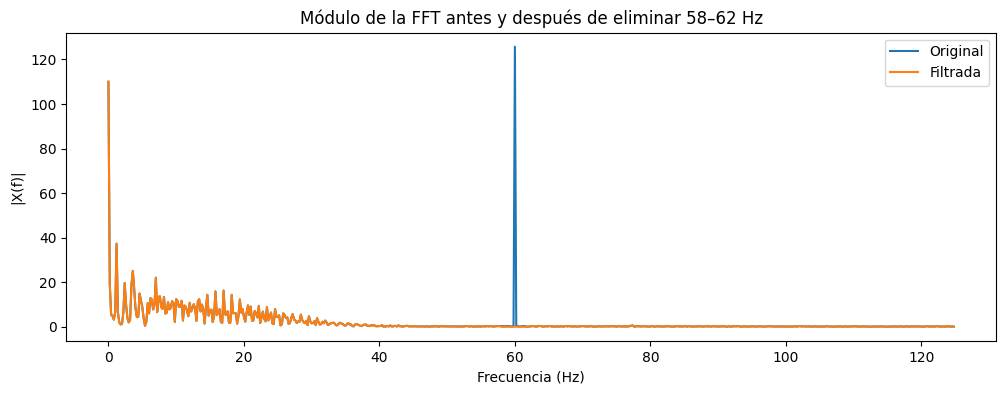

In [66]:
def quitar_banda(x, fs, f_min, f_max): #Elimina con la FFT las frecuencias entre f_min y f_max (y su espejo) y regresa al tiempo con la IFFT.
    N = len(x)
    X = np.fft.fft(x)
    f = np.arange(N) * fs / N                       # frecuencia de cada coeficiente
    banda = (f >= f_min) & (f <= f_max)             # mitad positiva
    espejo = (f >= fs - f_max) & (f <= fs - f_min)  # mitad negativa (espejo)
    X_filtrada = X.copy()
    X_filtrada[banda | espejo] = 0
    x_filtrada = np.real(np.fft.ifft(X_filtrada))   # transformada inversa
    return x_filtrada, X, X_filtrada, f


ecg_filtrada, X_ecg, X_ecg_filtrada, f_ecg = quitar_banda(ecg, fs, 58, 62)

mitad = len(f_ecg) // 2
plt.figure(figsize=(12, 4))
plt.plot(f_ecg[:mitad], np.abs(X_ecg[:mitad]), label='Original')
plt.plot(f_ecg[:mitad], np.abs(X_ecg_filtrada[:mitad]), label='Filtrada')
plt.xlabel('Frecuencia (Hz)')
plt.ylabel('|X(f)|')
plt.title('Módulo de la FFT antes y después de eliminar 58–62 Hz')
plt.legend()
plt.show()

### Comprobación en el tiempo

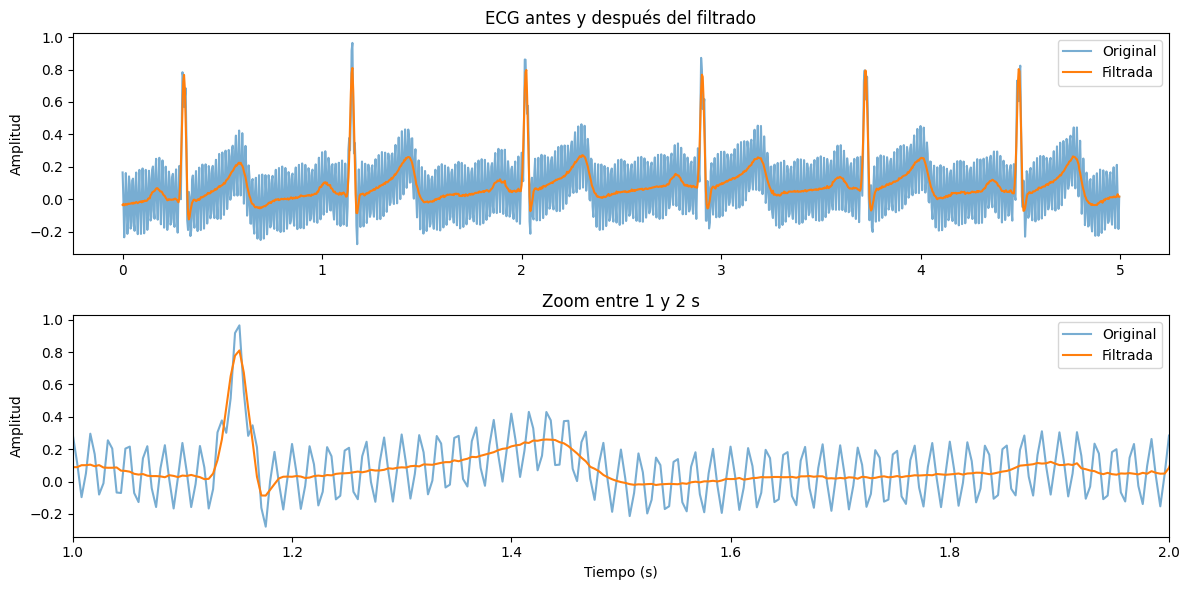

In [67]:
plt.figure(figsize=(12, 6))
plt.subplot(2, 1, 1)
plt.plot(t_ecg, ecg, label='Original', alpha=0.6)
plt.plot(t_ecg, ecg_filtrada, label='Filtrada')
plt.ylabel('Amplitud')
plt.title('ECG antes y después del filtrado')
plt.legend()

plt.subplot(2, 1, 2)                     # zoom de 1 s para ver el detalle
plt.plot(t_ecg, ecg, label='Original', alpha=0.6)
plt.plot(t_ecg, ecg_filtrada, label='Filtrada')
plt.xlim(1, 2)
plt.xlabel('Tiempo (s)')
plt.ylabel('Amplitud')
plt.title('Zoom entre 1 y 2 s')
plt.legend()
plt.tight_layout()
plt.show()

En el tiempo, la señal filtrada conserva los complejos QRS, las ondas T y la forma general del ECG, pero ya no tiene las oscilaciones rápidas de 60 Hz. En el zoom se ve que la línea de base, que antes estaba cubierta por el ruido, ahora es suave y permite distinguir con claridad cada onda. El pico del QRS queda un poco más bajo que en la señal original, porque allí el ruido de 60 Hz se sumaba encima del complejo y aumentaba su altura.

### Comprobación con el periodograma
Se calcula el periodograma de Welch de la señal reconstruida con la transformada inversa, con las dos funciones.

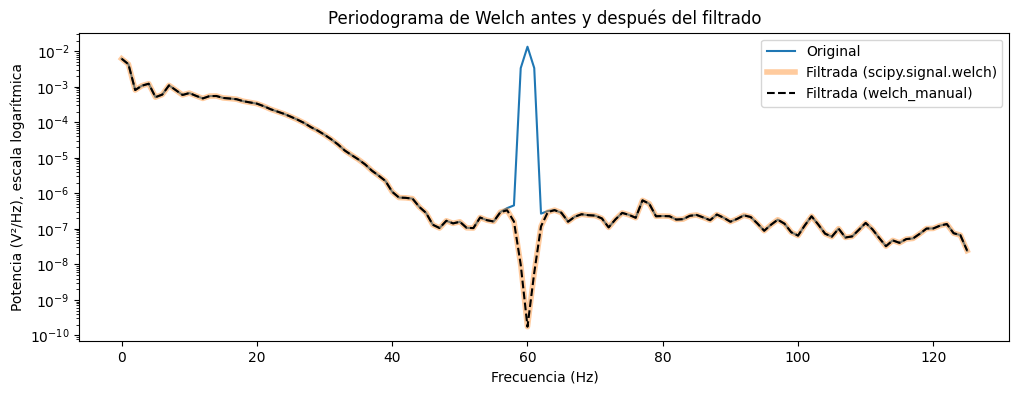

Potencia entre 58 y 62 Hz antes:   0.020227 V²
Potencia entre 58 y 62 Hz después: 0.000000 V²
Reducción: 100.00 %
Potencia entre 0,5 y 40 Hz (ECG) antes: 0.01790 V², después: 0.01790 V²
Diferencia máxima entre la función manual y la librería (señal filtrada): 5.204170427930421e-18


In [68]:
f_man2, P_man2 = welch_manual(ecg_filtrada, fs, L, D)
f_lib2, P_lib2 = welch(ecg_filtrada, fs, window='hann', nperseg=L, noverlap=D, detrend=False)

plt.figure(figsize=(12, 4))
plt.semilogy(f_man, P_man, label='Original')
plt.semilogy(f_lib2, P_lib2, linewidth=4, alpha=0.4, label='Filtrada (scipy.signal.welch)')
plt.semilogy(f_man2, P_man2, 'k--', label='Filtrada (welch_manual)')
plt.xlabel('Frecuencia (Hz)')
plt.ylabel('Potencia (V²/Hz), escala logarítmica')
plt.title('Periodograma de Welch antes y después del filtrado')
plt.legend()
plt.show()


def potencia_banda(f, P, f_min, f_max):
    """Potencia total entre f_min y f_max (suma de la PSD por la resolución en frecuencia)."""
    banda = (f >= f_min) & (f <= f_max)
    return np.sum(P[banda]) * (f[1] - f[0])


antes = potencia_banda(f_man, P_man, 58, 62)
despues = potencia_banda(f_man2, P_man2, 58, 62)
print(f"Potencia entre 58 y 62 Hz antes:   {antes:.6f} V²")
print(f"Potencia entre 58 y 62 Hz después: {despues:.6f} V²")
print(f"Reducción: {100 * (1 - despues / antes):.2f} %")
print(f"Potencia entre 0,5 y 40 Hz (ECG) antes: {potencia_banda(f_man, P_man, 0.5, 40):.5f} V², después: {potencia_banda(f_man2, P_man2, 0.5, 40):.5f} V²")
print("Diferencia máxima entre la función manual y la librería (señal filtrada):", np.max(np.abs(P_man2 - P_lib2)))

### Análisis del resultado
El periodograma de la señal reconstruida con la transformada inversa confirma que el ruido se eliminó: el pico de 60 Hz desapareció por completo y la potencia entre 58 y 62 Hz bajó prácticamente a cero. En su lugar queda una pequeña "muesca" en el periodograma, que corresponde a la banda que se puso en cero.

Al mismo tiempo, la información del ECG se conservó. La potencia entre 0,5 y 40 Hz es la misma antes y después del filtrado, y el resto del espectro no cambió, porque el filtro solo actuó sobre una banda muy estrecha alrededor de 60 Hz. Este tipo de filtro, que elimina una banda angosta y deja pasar todo lo demás, se conoce como filtro rechaza banda. Es la opción adecuada para este caso, porque el ruido estaba concentrado en una sola frecuencia y lejos de la banda útil del ECG.

Por último, la función manual y la de la librería también coinciden con la señal filtrada, lo que confirma de nuevo que la función del punto 4.5 calcula correctamente el periodograma de Welch. La ventaja de la función de la librería es que ofrece más opciones, como otras ventanas o la eliminación de la tendencia de cada segmento. La de la función manual es que permite entender exactamente qué cálculo se hace en cada paso.


# Punto 4.7

Realice un análisis de frecuencia a través del periodograma de Welch de una señal de EKG de un paciente sano y otra de un paciente con alguna condición cardiaca que en el proyecto 1 hayan identificado que presentaba diferencias, si no encontró diferencias, elija un par al azar. Realice un análisis comparativo de las señales según lo que le indiquen los periodogramas. (Usar una ventana Hanning, y justificar la elección del solapamiento y el ancho de la ventana) (25%)

### Elección de los pacientes

En el proyecto 1, la taquicardia supraventricular (SVT) fue el ritmo que más se diferenció de los demás: su suma de frecuencias significativas en bicoherencia fue claramente menor que la del ritmo sinusal, con un tamaño del efecto grande. Por eso se compara:

- **Paciente sano:** ritmo sinusal (SR), sin condiciones adicionales.
- **Paciente con condición:** taquicardia supraventricular (SVT), sin condiciones adicionales. 

Los dos tienen la misma edad y el mismo género, para que la diferencia entre sus espectros se deba al ritmo y no a otros factores.

In [69]:
RUTA_DIAGNOSTICOS = "Diagnostics.xlsx"
RUTA_SENALES = "ECGDataDenoised"
SANO = "MUSE_20180209_120237_19000"
CONDICION = "MUSE_20180712_151222_03000"
fs_ekg = 500        # Hz (base de datos Chapman-Shaoxing)

diag = pd.read_excel(RUTA_DIAGNOSTICOS)
columnas = ["FileName", "Rhythm", "Beat", "PatientAge", "Gender", "VentricularRate"]
diag[diag["FileName"].isin([SANO, CONDICION])][columnas]

,FileName,Rhythm,Beat,PatientAge,Gender,VentricularRate
96,MUSE_20180209_120237_19000,SR,NONE,56,MALE,75
10432,MUSE_20180712_151222_03000,SVT,NONE,56,MALE,136


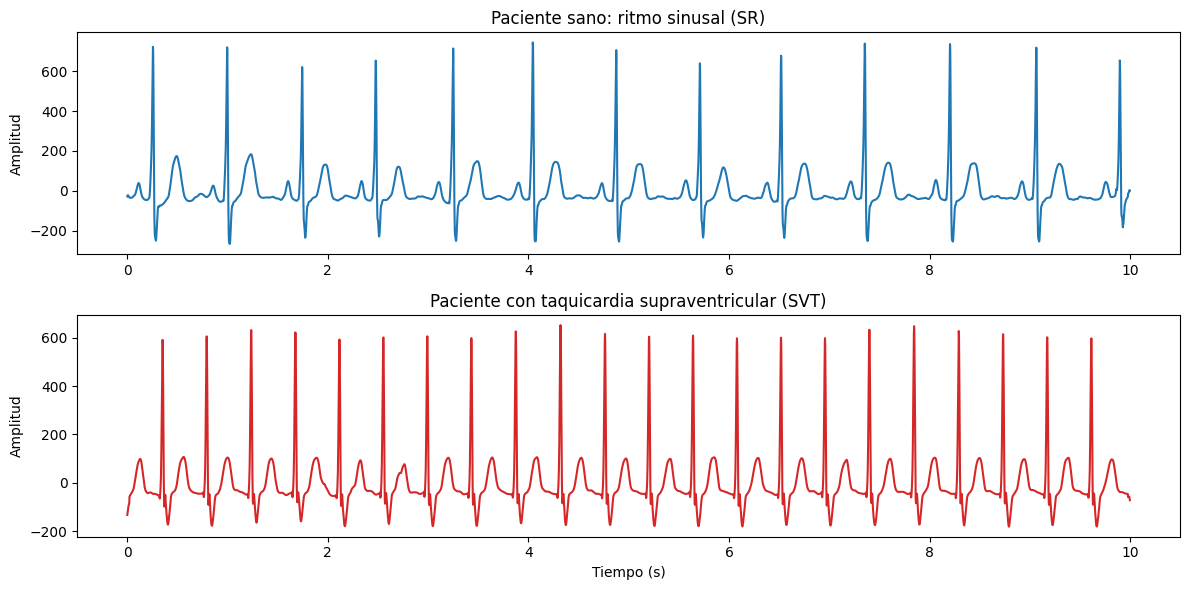

In [70]:
def cargar_derivacion_II(nombre):
    datos = pd.read_csv(RUTA_SENALES + "/" + nombre + ".csv", header=None)
    x = datos[1].to_numpy()
    return x - np.mean(x)          # se quita la media para que el valor en 0 Hz no domine el espectro


x_sano = cargar_derivacion_II(SANO)
x_svt = cargar_derivacion_II(CONDICION)
t_ekg = np.arange(len(x_sano)) / fs_ekg

plt.figure(figsize=(12, 6))
plt.subplot(2, 1, 1)
plt.plot(t_ekg, x_sano)
plt.title('Paciente sano: ritmo sinusal (SR)')
plt.ylabel('Amplitud')
plt.subplot(2, 1, 2)
plt.plot(t_ekg, x_svt, color='tab:red')
plt.title('Paciente con taquicardia supraventricular (SVT)')
plt.xlabel('Tiempo (s)')
plt.ylabel('Amplitud')
plt.tight_layout()
plt.show()

### Elección del ancho de la ventana y del solapamiento
Se escogió una ventana de L = 1000 muestras, es decir, 2 s, con lo que la resolución en frecuencia es fs/L = 500/1000 = 0,5 Hz. Esta resolución es necesaria porque en un ECG la información del ritmo aparece en el periodograma como un pico en la frecuencia cardíaca y una serie de picos en sus múltiplos, los armónicos. En el paciente sano, con unos 75 latidos por minuto, esos picos están separados apenas 1,25 Hz. Con una ventana de 1 s la resolución sería de 1 Hz y los picos quedarían prácticamente pegados, mientras que con 0,5 Hz se pueden distinguir. Además, cada ventana de 2 s contiene al menos dos latidos completos. No se usó una ventana más larga porque cada registro dura solo 10 s, y con ventanas mayores quedarían muy pocos segmentos para promediar, lo que haría el periodograma más ruidoso.

El solapamiento elegido es de D = 500 muestras, es decir, del 50 %, por la misma razón que en el punto 4.6. La ventana de Hann se anula en los extremos de cada segmento, y con un 50 % de solapamiento las ventanas consecutivas suman un valor constante, así que todas las muestras de la señal pesan lo mismo en el promedio. Además, el número de segmentos pasa de 5 a 9, lo que reduce la variabilidad del periodograma.

Diferencia máxima manual vs librería (sano): 1.8189894035458565e-12
Diferencia máxima manual vs librería (SVT):  9.094947017729282e-12


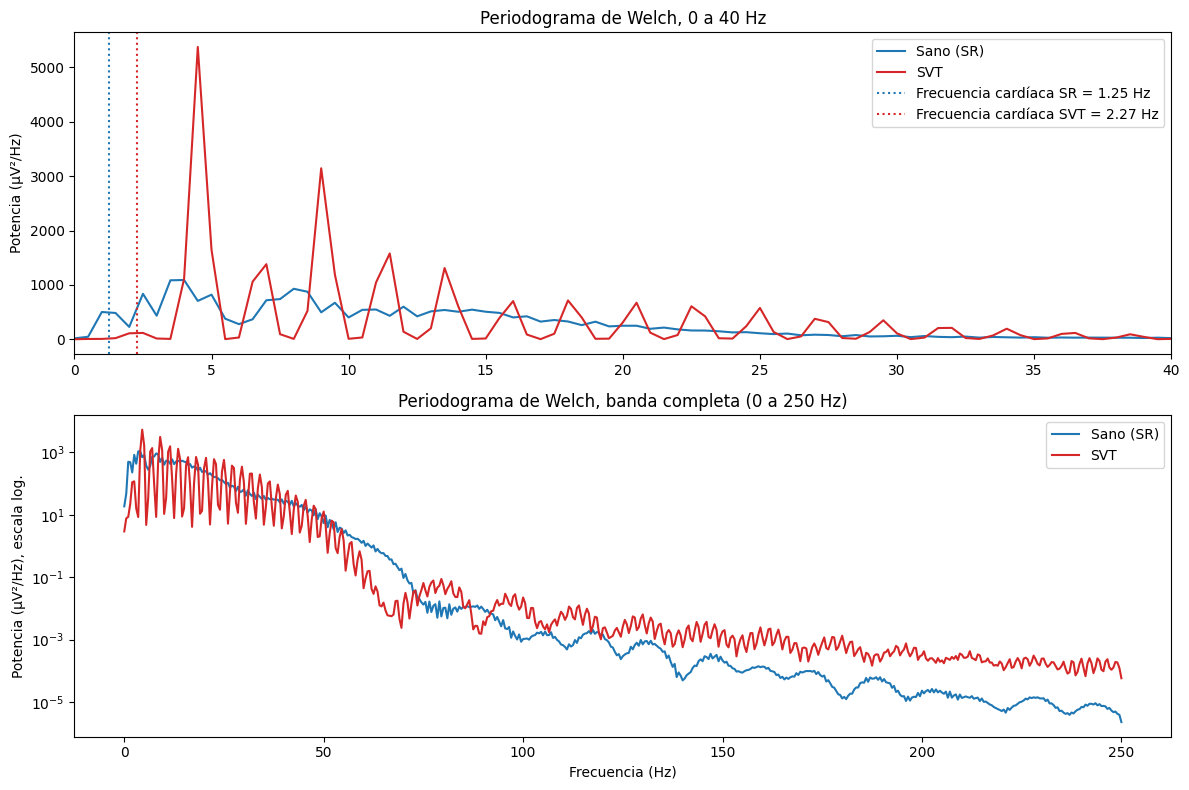

In [71]:
L_ekg = 1000     # 2 s -> resolución de 0,5 Hz
D_ekg = 500      # 50 % de solapamiento

f_s, P_sano = welch_manual(x_sano, fs_ekg, L_ekg, D_ekg)
f_v, P_svt = welch_manual(x_svt, fs_ekg, L_ekg, D_ekg)

# Comparación con la librería
_, P_sano_lib = welch(x_sano, fs_ekg, window='hann', nperseg=L_ekg, noverlap=D_ekg, detrend=False)
_, P_svt_lib = welch(x_svt, fs_ekg, window='hann', nperseg=L_ekg, noverlap=D_ekg, detrend=False)
print("Diferencia máxima manual vs librería (sano):", np.max(np.abs(P_sano - P_sano_lib)))
print("Diferencia máxima manual vs librería (SVT): ", np.max(np.abs(P_svt - P_svt_lib)))

# Frecuencia cardíaca de cada paciente en Hz sacado de  Diagnostics.xlsx
fc_sano = diag.loc[diag["FileName"] == SANO, "VentricularRate"].values[0] / 60
fc_svt = diag.loc[diag["FileName"] == CONDICION, "VentricularRate"].values[0] / 60

plt.figure(figsize=(12, 8))
plt.subplot(2, 1, 1)
plt.plot(f_s, P_sano, label='Sano (SR)')
plt.plot(f_v, P_svt, color='tab:red', label='SVT')
plt.axvline(fc_sano, color='tab:blue', linestyle=':', label=f'Frecuencia cardíaca SR = {fc_sano:.2f} Hz')
plt.axvline(fc_svt, color='tab:red', linestyle=':', label=f'Frecuencia cardíaca SVT = {fc_svt:.2f} Hz')
plt.xlim(0, 40)
plt.ylabel('Potencia (µV²/Hz)')
plt.title('Periodograma de Welch, 0 a 40 Hz')
plt.legend()

plt.subplot(2, 1, 2)
plt.semilogy(f_s, P_sano, label='Sano (SR)')
plt.semilogy(f_v, P_svt, color='tab:red', label='SVT')
plt.xlabel('Frecuencia (Hz)')
plt.ylabel('Potencia (µV²/Hz), escala log.')
plt.title('Periodograma de Welch, banda completa (0 a 250 Hz)')
plt.legend()
plt.tight_layout()
plt.show()

### Comparación numérica
Para comparar los dos periodogramas con números, se calcula para cada paciente la frecuencia donde está la máxima potencia y el porcentaje de la potencia total entre 0,5 y 40 Hz que cae en tres bandas. La banda de 0,5 a 5 Hz contiene la frecuencia cardíaca y las ondas P y T, que son lentas. La banda de 5 a 15 Hz contiene la mayor parte de la energía del complejo QRS. La banda de 15 a 40 Hz contiene las componentes más rápidas del QRS.

In [72]:
def resumen_espectro(f, P, nombre): #Frecuencia de máxima potencia y porcentaje de potencia por bandas.
    total = potencia_banda(f, P, 0.5, 40)
    return {"Paciente": nombre,
            "Frecuencia de máx. potencia (Hz)": f[np.argmax(P)],
            "% potencia 0,5–5 Hz": 100 * potencia_banda(f, P, 0.5, 5) / total,
            "% potencia 5–15 Hz": 100 * potencia_banda(f, P, 5, 15) / total,
            "% potencia 15–40 Hz": 100 * potencia_banda(f, P, 15, 40) / total}


tabla_47 = pd.DataFrame([resumen_espectro(f_s, P_sano, "Sano (SR)"),
                         resumen_espectro(f_v, P_svt, "SVT")])
tabla_47.round(2)

,Paciente,Frecuencia de máx. potencia (Hz),"% potencia 0,5–5 Hz",% potencia 5–15 Hz,% potencia 15–40 Hz
0,Sano (SR),4.0,26.17,49.68,29.72
1,SVT,4.5,28.90,48.19,28.62


### Análisis comparativo
En el tiempo se observa que el paciente sano tiene 13 latidos en 10 s, mientras que el paciente con taquicardia supraventricular tiene unos 22, lo que concuerda con sus frecuencias cardíacas de 1,25 Hz y 2,27 Hz. Además, en la SVT los latidos están separados por intervalos casi idénticos, mientras que en el ritmo sinusal esa separación varía un poco de un latido a otro.

El periodograma de la SVT muestra una serie de picos angostos separados unos 2,25 Hz, que corresponden a la frecuencia cardíaca y sus armónicos. Esto ocurre porque el ECG es una señal casi periódica, y por eso concentra su potencia en la frecuencia de repetición y en sus múltiplos. Como el ritmo de la SVT es muy regular, los picos son altos y bien definidos. El máximo está en 4,5 Hz, que es el segundo armónico, debido a que la forma del QRS y de la onda T aporta más energía en esa frecuencia.

En el paciente sano, en cambio, el periodograma es mucho más suave y solo se distinguen algunos picos en las frecuencias bajas. Esto se debe a que sus armónicos están más juntos, cada 1,25 Hz, y a que la variación natural del intervalo entre latidos dispersa cada armónico en una franja de frecuencias. Por esta razón su pico máximo, en 4 Hz, es unas cinco veces menor que el de la SVT.

Por otro lado, la potencia por bandas es casi igual en los dos pacientes, con cerca del 27 % entre 0,5 y 5 Hz, del 49 % entre 5 y 15 Hz y del 29 % entre 15 y 40 Hz. Esto indica que la forma de cada latido es parecida, con complejos QRS angostos, lo cual es esperable porque en la SVT el impulso recorre los ventrículos por la vía normal. En consecuencia, la diferencia entre los dos ritmos no está en cuánta energía hay en cada banda, sino en cómo se organiza, ya que en la SVT se concentra en armónicos definidos y en el ritmo sinusal se reparte de forma más continua.

Finalmente, la función manual y la de la librería coinciden. La diferencia de 10⁻¹² es mayor que en los puntos anteriores solo porque estas potencias alcanzan valores de miles, de modo que en proporción sigue siendo un error de redondeo.


# Punto 4.8. Conclusiones y referencias

### Conclusiones
1. El periodograma de Welch se puede calcular directamente con la DFT: se divide la señal en segmentos solapados, se aplica una ventana a cada uno, se calcula el espectro de potencia de cada segmento y se promedian. La función implementada coincide con scipy.signal.welch hasta el error de redondeo, es decir, diferencias del orden de 10⁻¹⁶ o menores.
2. Promediar varios segmentos hace que el periodograma de Welch sea más estable que el espectro de una sola DFT. A cambio se pierde resolución en frecuencia, porque cada segmento es más corto que la señal completa. El ancho de la ventana se debe escoger según lo que se quiere distinguir; 1 Hz bastó para encontrar el ruido de 60 Hz, mientras que para separar los armónicos de la frecuencia cardíaca se necesitaron 0,5 Hz.
3. La ventana de Hann reduce la fuga espectral, y con un 50 % de solapamiento todas las muestras de la señal pesan lo mismo y aumenta el número de segmentos para promediar.
4. La señal senecg.mat estaba contaminada con interferencia de la red eléctrica de 60 Hz, que en el periodograma aparece como un pico unas 10.000 veces mayor que las frecuencias vecinas. Al eliminar con la FFT la banda de 58 a 62 Hz, el pico desapareció, mientras que la potencia del ECG entre 0,5 y 40 Hz se mantuvo igual. Como el ruido estaba en una banda estrecha y fuera de la banda del ECG, un filtro rechaza banda fue suficiente.
5. Al comparar con el periodograma de Welch un ritmo sinusal y una taquicardia supraventricular, la diferencia principal no estuvo en la potencia por bandas, que fue casi igual, sino en la organización del espectro. En la SVT la potencia se concentra en picos angostos en la frecuencia cardíaca y sus armónicos, debido a que su ritmo es rápido y regular, mientras que en el ritmo sinusal los armónicos están más juntos y se dispersan por la variación natural de la frecuencia cardíaca. Esto concuerda con el proyecto 1, donde la SVT mostró menos frecuencias significativas en la bicoherencia que el ritmo sinusal.

### Referencias
1. J. G. Proakis y D. G. Manolakis, *Digital Signal Processing: Principles, Algorithms and Applications*, 4.ª ed. Prentice Hall, 2007.
2. P. D. Welch, "The use of fast Fourier transform for the estimation of power spectra: a method based on time averaging over short, modified periodograms", *IEEE Transactions on Audio and Electroacoustics*, vol. 15, n.º 2, pp. 70–73, 1967.
3. F. J. Harris, "On the use of windows for harmonic analysis with the discrete Fourier transform", *Proceedings of the IEEE*, vol. 66, n.º 1, pp. 51–83, 1978.
4. J. Zheng *et al.*, "Optimal Multi-Stage Arrhythmia Classification Approach", *Scientific Reports*, vol. 10, 2898, 2020.
5. Documentación de SciPy, `scipy.signal.welch`: https://docs.scipy.org/doc/scipy/reference/generated/scipy.signal.welch.html